# Notebook 01 — Data Validation

**Purpose:** Load all 6 CSV files, check for missing data, verify date ranges, and plot basic price charts.

**Run this first, before anything else.**

Before running: make sure all 6 CSV files are in the `data/` folder.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))  # add project root to path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (14, 5)
plt.rcParams['font.size'] = 11

print("Libraries loaded successfully.")
print(f"Pandas version: {pd.__version__}")
print(f"NumPy version: {np.__version__}")

Libraries loaded successfully.
Pandas version: 3.0.2
NumPy version: 2.4.4


## Step 1 — Check which CSV files are present

In [2]:
from src.data_loader import check_data_files, DATA_DIR

print(f"Looking for files in: {DATA_DIR}")
print()

status = check_data_files()
all_ok = True
for fname, exists in status.items():
    icon = "OK  " if exists else "MISSING"
    print(f"  [{icon}]  {fname}")
    if not exists:
        all_ok = False

print()
if all_ok:
    print("All 6 files found. Proceed to the next cell.")
else:
    print("STOP: Copy the missing files into the data/ folder, then re-run this cell.")

Looking for files in: C:\Users\omtej\Projects\2020_algo_based\data

  [OK  ]  eurusd_1h.csv
  [OK  ]  eurusd_4h.csv
  [OK  ]  eurusd_1d.csv
  [OK  ]  dxy_1h.csv
  [OK  ]  vix_1d.csv
  [OK  ]  us10y_1d.csv

All 6 files found. Proceed to the next cell.


## Step 2 — Load all data files

In [3]:
from src.data_loader import load_all_data

data = load_all_data()
print("\nData dictionary keys:", list(data.keys()))

  Loading raw data files
  [OK] EURUSD 1H: 39,033 rows | 2020-01-01 → 2026-04-06
  [OK] EURUSD 4H: 39,033 rows | 2020-01-01 → 2026-04-06
  [OK] EURUSD Daily: 39,033 rows | 2020-01-01 → 2026-04-06
  [OK] DXY 1H: 39,033 rows | 2020-01-01 → 2026-04-06
  [OK] VIX Daily: 39,033 rows | 2020-01-01 → 2026-04-06
  [OK] US10Y Daily: 39,033 rows | 2020-01-01 → 2026-04-06
-------------------------------------------------------
  All files loaded successfully.

Data dictionary keys: ['eurusd_1h', 'eurusd_4h', 'eurusd_1d', 'dxy_1h', 'vix_1d', 'us10y_1d']


## Step 3 — Inspect EURUSD 1H data

In [4]:
eurusd_1h = data['eurusd_1h']

print("Shape:", eurusd_1h.shape)
print("Date range:", eurusd_1h.index[0], "to", eurusd_1h.index[-1])
print("\nFirst 5 rows:")
eurusd_1h.head()

Shape: (39033, 5)
Date range: 2020-01-01 21:00:00 to 2026-04-06 20:00:00

First 5 rows:


,Open,High,Low,Close,Volume
Price,,,,,
2020-01-01 21:00:00,1.12122,1.12165,1.12081,1.12146,0
2020-01-01 22:00:00,1.12146,1.12218,1.12140,1.12188,0
2020-01-01 23:00:00,1.12188,1.12191,1.12157,1.12183,0
2020-01-02 00:00:00,1.12183,1.12245,1.12180,1.12210,0
2020-01-02 01:00:00,1.12209,1.12246,1.12183,1.12223,0


In [5]:
print("Missing values per column:")
print(eurusd_1h.isna().sum())
print()
print("Basic statistics:")
eurusd_1h.describe().round(6)

Missing values per column:
Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64

Basic statistics:


,Open,High,Low,Close,Volume
count,39033.000000,39033.000000,39033.000000,39033.000000,39033.0
mean,1.114435,1.115161,1.113728,1.114445,0.0
std,0.057354,0.057280,0.057417,0.057352,0.0
min,0.953920,0.955940,0.953580,0.953920,0.0
25%,1.076320,1.076900,1.075680,1.076320,0.0
50%,1.102790,1.103570,1.102140,1.102790,0.0
75%,1.166250,1.166820,1.165620,1.166250,0.0
max,1.234020,1.234940,1.233350,1.234030,0.0


## Step 4 — Plot EURUSD 1H close price

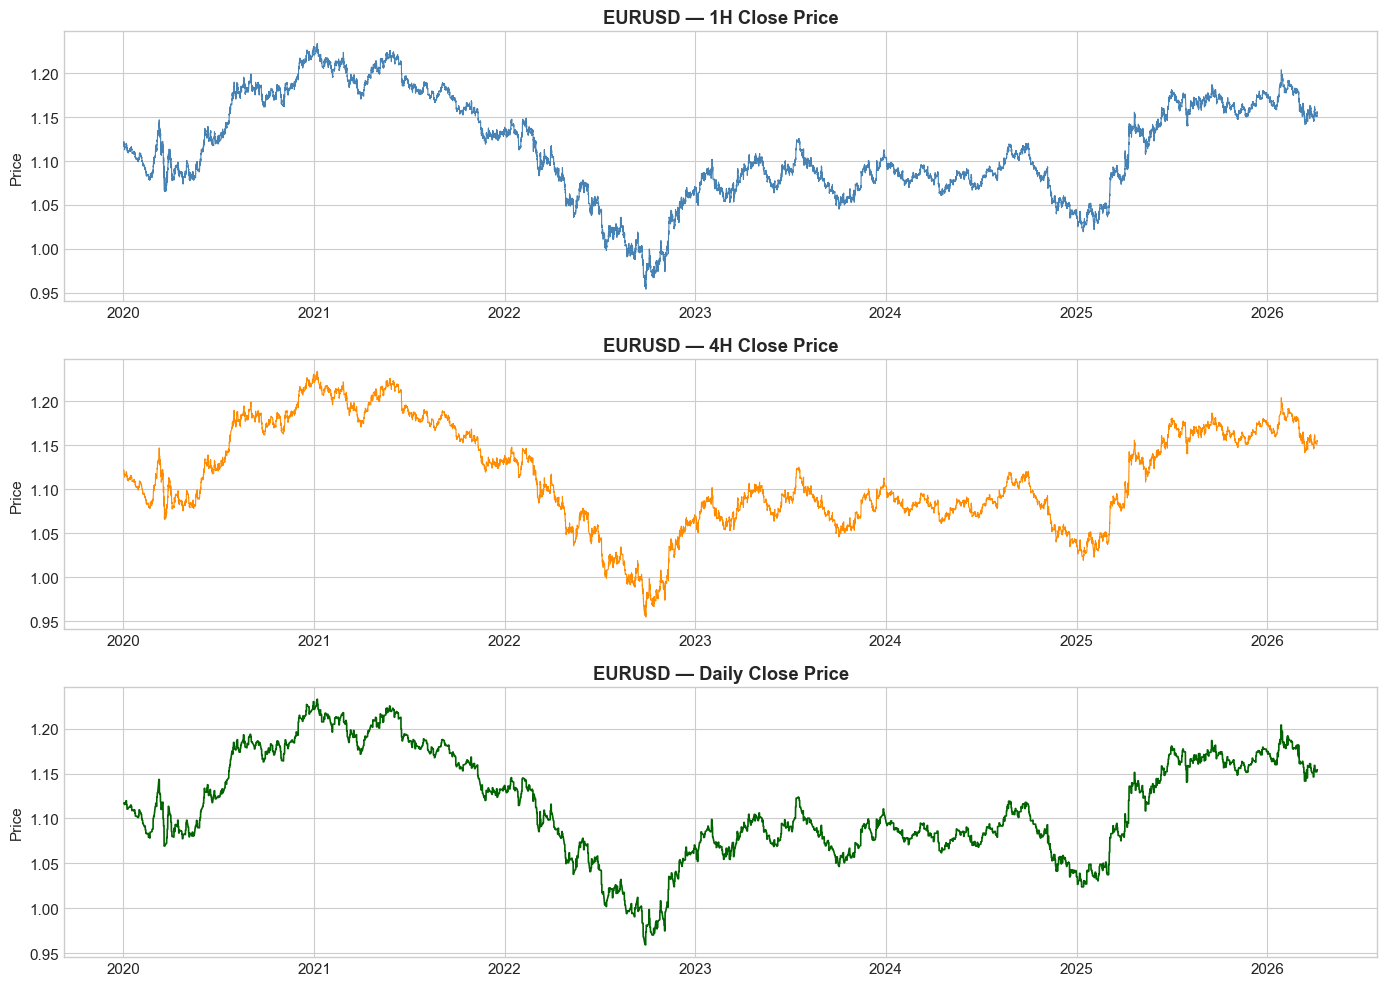

Chart saved to results/01_eurusd_price_charts.png


In [6]:
fig, axes = plt.subplots(3, 1, figsize=(14, 10))

# 1H close
axes[0].plot(eurusd_1h.index, eurusd_1h['Close'], linewidth=0.8, color='steelblue')
axes[0].set_title('EURUSD — 1H Close Price', fontweight='bold')
axes[0].set_ylabel('Price')

# 4H close
eurusd_4h = data['eurusd_4h']
axes[1].plot(eurusd_4h.index, eurusd_4h['Close'], linewidth=0.8, color='darkorange')
axes[1].set_title('EURUSD — 4H Close Price', fontweight='bold')
axes[1].set_ylabel('Price')

# Daily close
eurusd_1d = data['eurusd_1d']
axes[2].plot(eurusd_1d.index, eurusd_1d['Close'], linewidth=1.2, color='darkgreen')
axes[2].set_title('EURUSD — Daily Close Price', fontweight='bold')
axes[2].set_ylabel('Price')

plt.tight_layout()
plt.savefig('../results/01_eurusd_price_charts.png', dpi=120, bbox_inches='tight')
plt.show()
print("Chart saved to results/01_eurusd_price_charts.png")

## Step 5 — Plot macro context: VIX and DXY

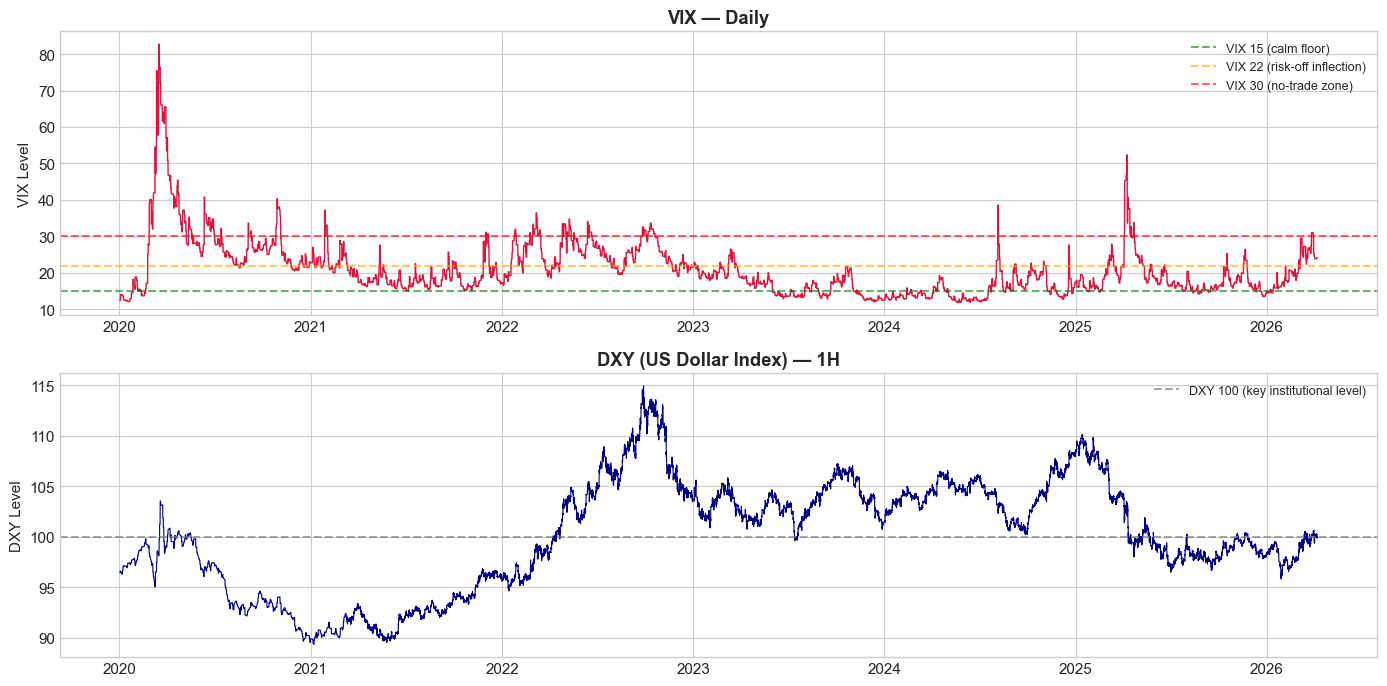

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7))

vix = data['vix_1d']
axes[0].plot(vix.index, vix['Close'], linewidth=1.0, color='crimson')
axes[0].axhline(15, linestyle='--', color='green',  alpha=0.6, label='VIX 15 (calm floor)')
axes[0].axhline(22, linestyle='--', color='orange', alpha=0.6, label='VIX 22 (risk-off inflection)')
axes[0].axhline(30, linestyle='--', color='red',    alpha=0.6, label='VIX 30 (no-trade zone)')
axes[0].set_title('VIX — Daily', fontweight='bold')
axes[0].set_ylabel('VIX Level')
axes[0].legend(fontsize=9)

dxy = data['dxy_1h']
axes[1].plot(dxy.index, dxy['Close'], linewidth=0.8, color='navy')
axes[1].axhline(100, linestyle='--', color='gray', alpha=0.7, label='DXY 100 (key institutional level)')
axes[1].set_title('DXY (US Dollar Index) — 1H', fontweight='bold')
axes[1].set_ylabel('DXY Level')
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.savefig('../results/01_macro_context_charts.png', dpi=120, bbox_inches='tight')
plt.show()

## Step 6 — Data quality summary

In [8]:
print("=" * 55)
print("  DATA QUALITY SUMMARY")
print("=" * 55)

for name, df in data.items():
    null_pct = df.isna().mean().mean() * 100
    status = "OK" if null_pct < 1 else "WARNING"
    print(f"  [{status}] {name:<15} | rows: {len(df):>6,} | null%: {null_pct:.2f}%")

print()
print("  If all rows show OK, proceed to Notebook 02.")
print("=" * 55)

  DATA QUALITY SUMMARY
  [OK] eurusd_1h       | rows: 39,033 | null%: 0.00%
  [OK] eurusd_4h       | rows: 39,033 | null%: 0.00%
  [OK] eurusd_1d       | rows: 39,033 | null%: 0.00%
  [OK] dxy_1h          | rows: 39,033 | null%: 0.00%
  [OK] vix_1d          | rows: 39,033 | null%: 0.00%
  [OK] us10y_1d        | rows: 39,033 | null%: 0.00%

  If all rows show OK, proceed to Notebook 02.


## ✅ Checkpoint

If you see:
- All 6 files with `[OK]` status
- Date range covers at least 2 years
- Charts showing EURUSD price history
- No high null% warnings

**→ Open `02_feature_engineering.ipynb` next.**